In [10]:
import os
import numpy as np
import matplotlib.pyplot as plt
from src.pickle_functions import load_from_pickle

In [49]:
result_folder = "results_old"
model_name = "late_fusion"
model_id = 1
with_neutral_class = False
with_n = "_n" if with_neutral_class else ""

In [115]:
def get_pred(task, model_id, result_folder, model_name):
    pred_name = "pred_" + task + "_" + str(model_id)
    root_folder = os.path.join(result_folder, model_name)
    pred_arr = load_from_pickle(pred_name, "predictions", root_folder)
    if task=="classes_pres":
        pred_arr = pred_arr[0]
    return pred_arr

In [53]:
def transform_label_arr(arr):
    new_arr = arr.T.tolist()
    return new_arr

In [69]:
def plot_scatter_plot(true_arr, pred_arr):
    emotions = ['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear']
    for i, emo_i in enumerate(emotions):
        true_emo_i = true_arr[i]
        pred_emo_i = pred_arr[i]
        plt.scatter(true_emo_i, pred_emo_i)
        plt.title(emo_i)
        plt.xlabel("True")
        plt.ylabel("Pred")
        plt.xlim([0, 3])
        plt.ylim([0, 3])
        plt.show()

In [94]:
def plot_scatter_plot_subplots(true_arr, pred_arr):
    emotions = ['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear']
    fig, axs = plt.subplots(2, 3, figsize=(20,12))
    for i, emo_i in enumerate(emotions):
        ax_i = axs[i//3, i%3]
        true_emo_i = true_arr[i]
        pred_emo_i = pred_arr[i]
        ax_i.scatter(true_emo_i, pred_emo_i)
        ax_i.set_title(emo_i)
        ax_i.set_xlim([0, 3])
        ax_i.set_ylim([0, 3])
        if i//3 == 1:
            ax_i.set_xlabel("True")
        if i%3 == 0:
            ax_i.set_ylabel("Pred")
    plt.show()

### True labels

In [54]:
true_all_name = "test_true_scores_all" + with_n
true_coa_name = "test_true_scores_coa" + with_n
true_pres_name = "test_true_classes_pres" + with_n
true_dom_name = "test_true_classes_dom" + with_n
true_all = load_from_pickle(true_all_name, "processed_folds", "cmu_mosei")
true_coa = load_from_pickle(true_coa_name, "processed_folds", "cmu_mosei")
true_pres = load_from_pickle(true_pres_name, "processed_folds", "cmu_mosei")
true_dom = load_from_pickle(true_dom_name, "processed_folds", "cmu_mosei")
true_all.shape

(4652, 6)

In [55]:
true_all = transform_label_arr(true_all)
true_coa = transform_label_arr(true_coa)
true_pres = transform_label_arr(true_pres[0])
true_dom = transform_label_arr(true_dom)
len(true_all)

6

### Task: all

In [100]:
task = "raw"

In [102]:
pred_all = get_pred(task, model_id, result_folder, model_name)
pred_all.shape

(4652, 6)

In [103]:
pred_all = transform_label_arr(pred_all)
len(pred_all)

6

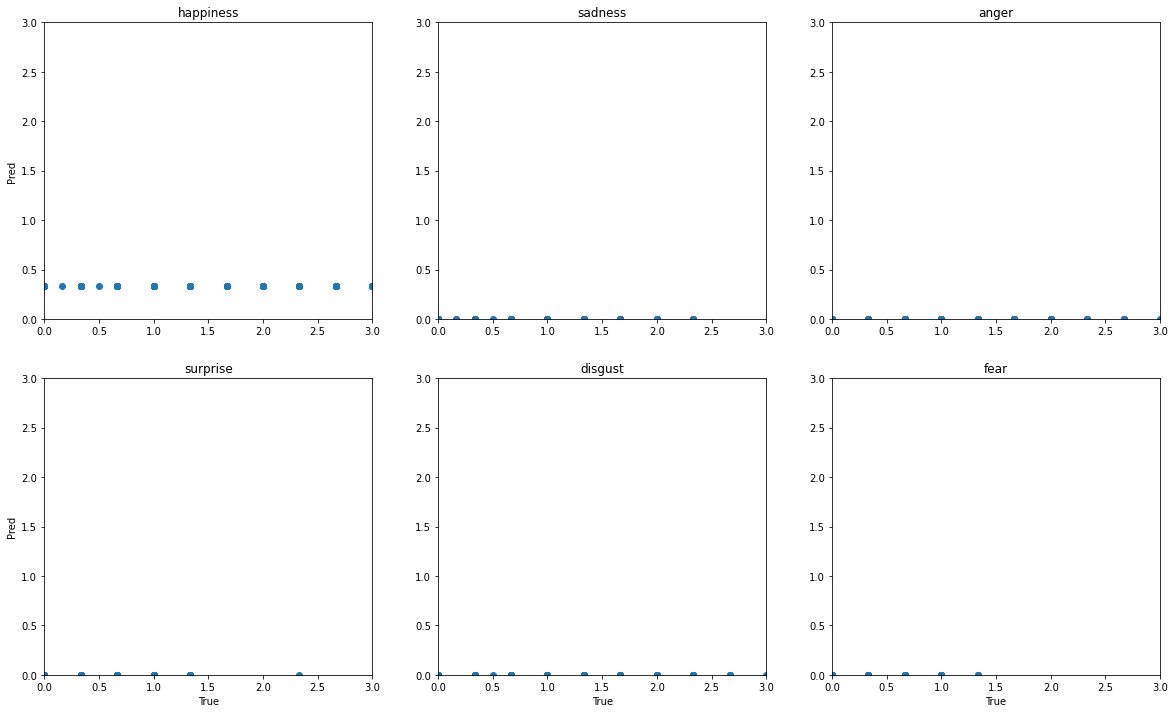

In [104]:
plot_scatter_plot_subplots(true_all, pred_all)

### Task: coarse

In [4]:
task = "scores_coa"

In [105]:
pred_coa = get_pred(task, model_id, result_folder, model_name)
pred_coa.shape

(4652, 6)

In [106]:
pred_coa = transform_label_arr(pred_coa)
len(pred_coa)

6

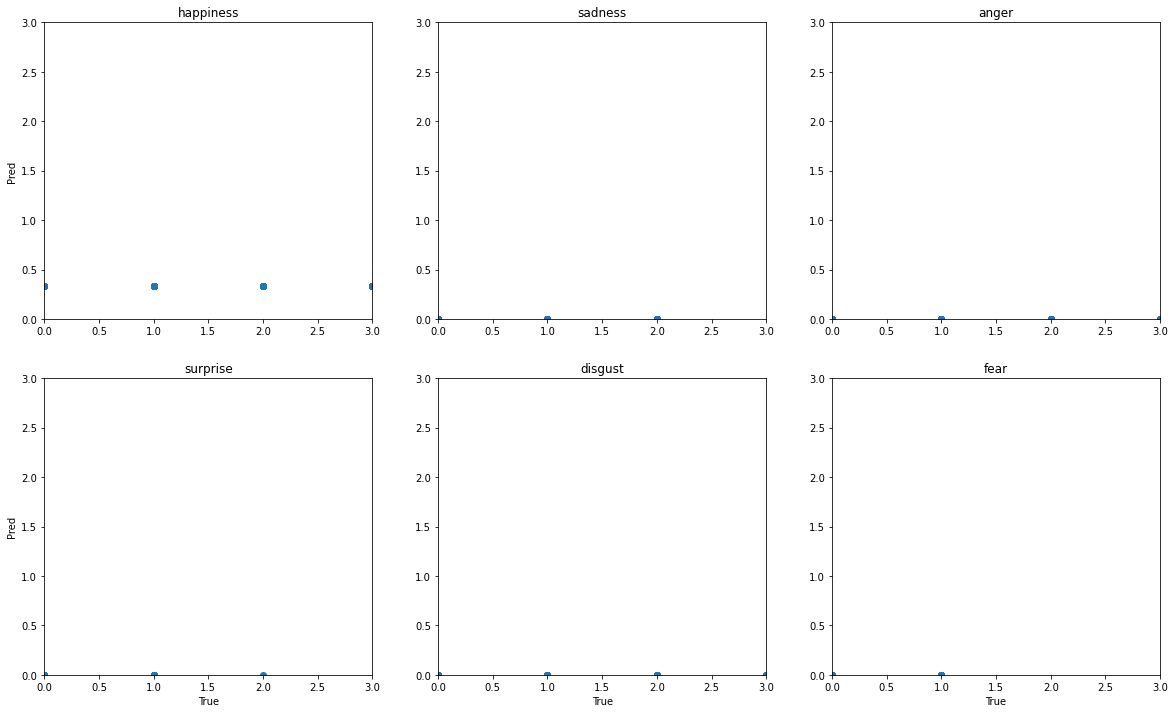

In [107]:
plot_scatter_plot_subplots(true_coa, pred_coa)

### Task: present

In [116]:
task = "classes_pres"

In [117]:
pred_pres = get_pred(task, model_id, result_folder, model_name)
pred_pres.shape

(4652, 6)

In [118]:
pred_pres = transform_label_arr(pred_pres)
len(pred_pres)

6

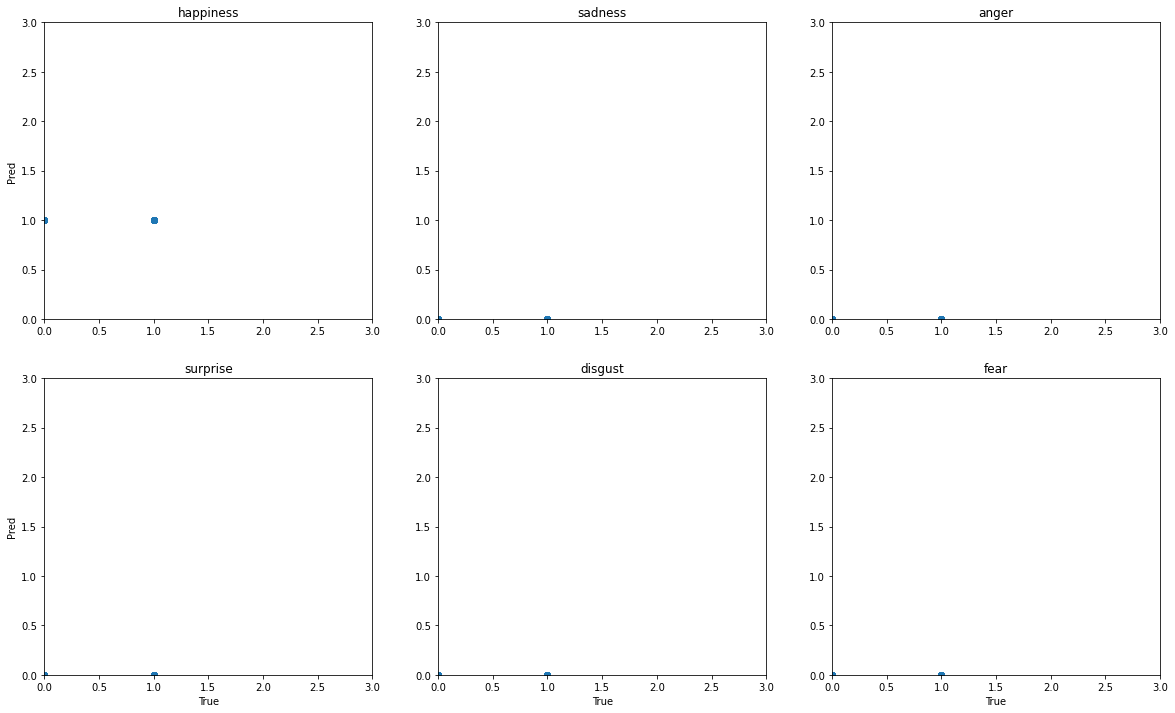

In [119]:
plot_scatter_plot_subplots(true_pres, pred_pres)

### Task: dominant

In [111]:
task = "classes_dom"

In [120]:
pred_dom = get_pred(task, model_id, result_folder, model_name)
pred_dom.shape

(4652, 6)

In [121]:
pred_dom = transform_label_arr(pred_dom)
len(pred_dom)

6

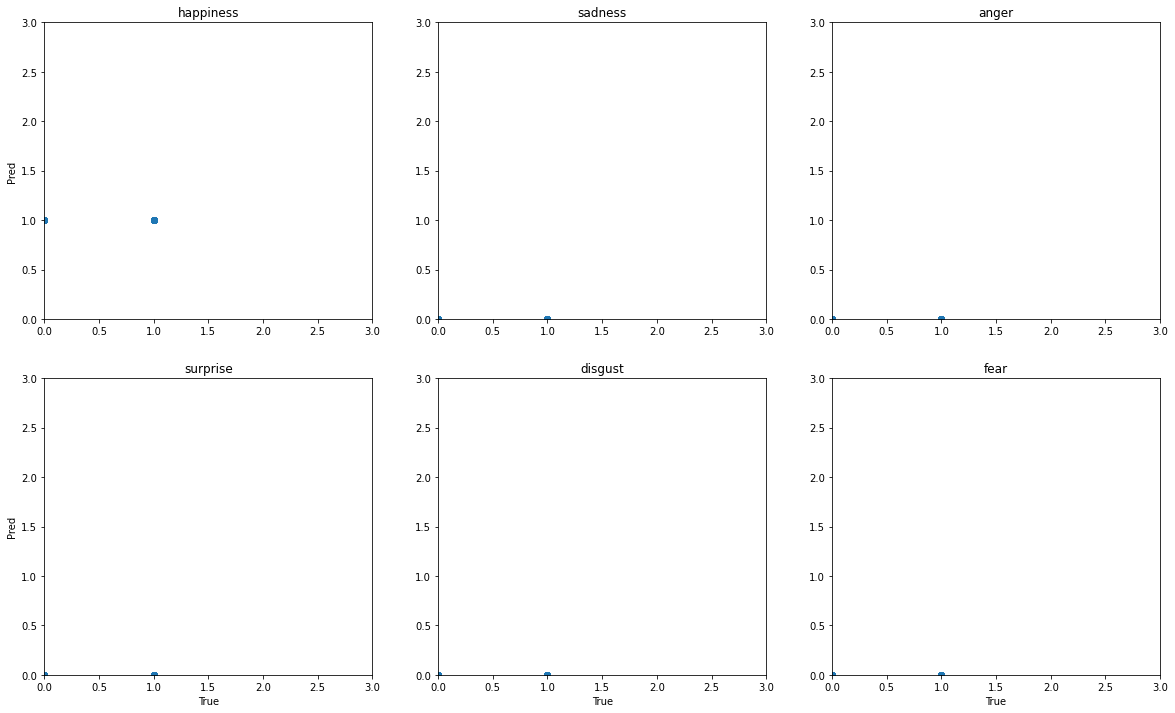

In [122]:
plot_scatter_plot_subplots(true_dom, pred_dom)